In [ ]:
import pandas as pd

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving finance_project_dataset_1000_records.csv to finance_project_dataset_1000_records.csv


**DATA CLEANING**

In [ ]:
df = pd.read_csv("finance_project_dataset_1000_records.csv")

In [ ]:
df.head()

,Transaction_ID,Date,Customer_ID,Customer_Name,Account_Type,Transaction_Type,Amount,Branch,Channel,Loan_Status,Credit_Score
0,T000001,2024-02-29,C1099,Diya Verma,Current,Credit,198698.91,Delhi,Online,Approved,439
1,T000002,2024-02-29,C1005,Aditya Kumar,Savings,Debit,31304.57,Kolkata,Online,Approved,729
2,T000003,2024-05-13,C1050,Meera Verma,Current,Credit,70413.26,Hyderabad,Online,Rejected,543
3,T000004,2024-05-05,C1028,Pooja Verma,Credit,Debit,164698.52,Kolkata,ATM,Approved,858
4,T000005,2024-03-27,C1248,Aarav Verma,Current,Debit,190769.58,Delhi,Online,Approved,848


In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction_ID    1000 non-null   object 
 1   Date              1000 non-null   object 
 2   Customer_ID       1000 non-null   object 
 3   Customer_Name     1000 non-null   object 
 4   Account_Type      1000 non-null   object 
 5   Transaction_Type  1000 non-null   object 
 6   Amount            1000 non-null   float64
 7   Branch            1000 non-null   object 
 8   Channel           1000 non-null   object 
 9   Loan_Status       1000 non-null   object 
 10  Credit_Score      1000 non-null   int64  
dtypes: float64(1), int64(1), object(9)
memory usage: 86.1+ KB


In [ ]:
df.shape

(1000, 11)

In [ ]:
import pandas as pd

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving finance_project_dataset_1000_records.csv to finance_project_dataset_1000_records.csv


In [ ]:
df = pd.read_csv("finance_project_dataset_1000_records.csv")

In [ ]:
df.isnull().sum()

,0
Transaction_ID,0
Date,0
Customer_ID,0
Customer_Name,0
Account_Type,0
Transaction_Type,0
Amount,0
Branch,0
Channel,0
Loan_Status,0


In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
df['Date'] = pd.to_datetime(df['Date'])

In [ ]:
df['Month'] = df['Date'].dt.month

**EDA (Exploratory Data Analysis)**

total transaction value

In [ ]:
df['Amount'].sum()

np.float64(102078418.44999999)

Average Transaction Value

In [ ]:
df['Amount'].mean()

np.float64(102078.41844999998)

Highest Transaction

In [ ]:
df['Amount'].max()

199825.01

Lowest Transaction

In [ ]:
df['Amount'].min()

757.35

Account Type Analysis

In [ ]:
df.groupby('Account_Type')['Amount'].sum()

,Amount
Account_Type,
Credit,32800787.54
Current,34870273.16
Savings,34407357.75


Branch Performance

In [ ]:
df.groupby('Branch')['Amount'].sum()

,Amount
Branch,
Bangalore,13612029.83
Chennai,14096888.57
Delhi,14288378.77
Hyderabad,14667170.27
Kolkata,13976606.11
Mumbai,15865011.43
Pune,15572333.47


In [ ]:
df.groupby('Branch')['Amount'].sum().sort_values(ascending=False)

,Amount
Branch,
Mumbai,15865011.43
Pune,15572333.47
Hyderabad,14667170.27
Delhi,14288378.77
Chennai,14096888.57
Kolkata,13976606.11
Bangalore,13612029.83


Monthly Transaction Trend

In [ ]:
df.groupby('Month')['Amount'].sum()

,Amount
Month,
1,9536527.20
2,9602750.06
3,9279684.99
4,7613221.46
5,8783453.19
6,7939512.00
7,9073899.98
8,6878844.45
9,9461187.77


Top 10 Customers

In [ ]:
df.groupby('Customer_ID')['Amount'].sum().sort_values(ascending=False).head(10)


,Amount
Customer_ID,
C1015,1066520.56
C1099,1060970.08
C1116,1051678.80
C1171,1033807.14
C1058,1000392.02
C1114,997568.90
C1234,996162.29
C1104,931763.73
C1061,917249.71


Loan Approval Rate

In [ ]:
df['Loan_Status'].value_counts(normalize=True) * 100


,proportion
Loan_Status,
Rejected,51.1
Approved,48.9


Channel Usage

In [ ]:
df['Channel'].value_counts()

,count
Channel,
Online,507
ATM,304
Bank,189


**VISUALISATION**

In [ ]:
import matplotlib.pyplot as plt

MONTHLY DATA

In [ ]:
monthly = df.groupby('Month')['Amount'].sum()
monthly

,Amount
Month,
1,9536527.20
2,9602750.06
3,9279684.99
4,7613221.46
5,8783453.19
6,7939512.00
7,9073899.98
8,6878844.45
9,9461187.77


📊 Graph 1: Monthly Transaction Trend (Line Chart)

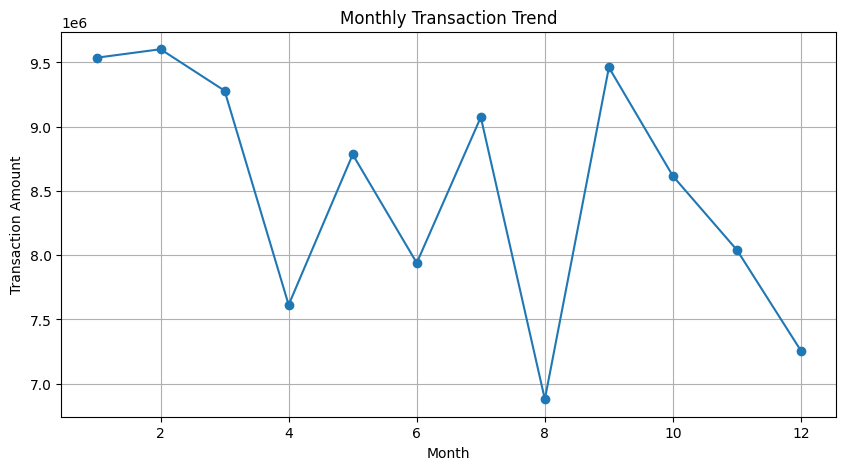

In [ ]:
plt.figure(figsize=(10,5))

monthly.plot(kind='line', marker='o')

plt.title("Monthly Transaction Trend")
plt.xlabel("Month")
plt.ylabel("Transaction Amount")

plt.grid(True)

plt.show()

line graph shows in which month transactions are high or low. it tells about the trend

📊 Graph 2: Branch Performance (Bar Chart)

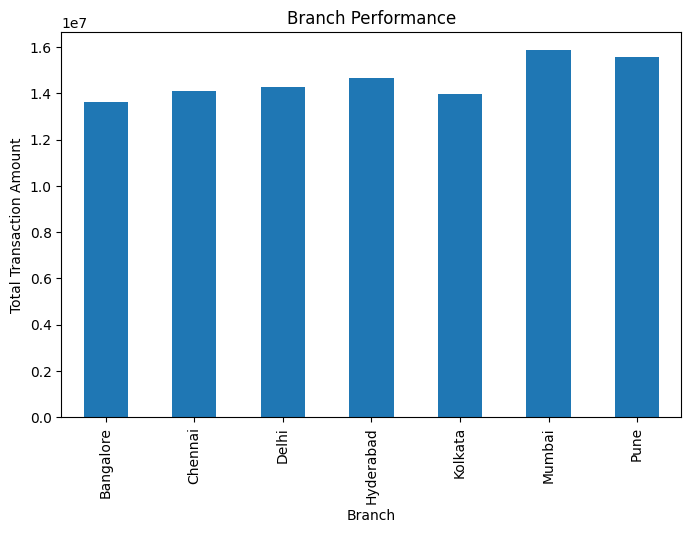

In [ ]:
branch = df.groupby('Branch')['Amount'].sum()

plt.figure(figsize=(8,5))

branch.plot(kind='bar')

plt.title("Branch Performance")
plt.xlabel("Branch")
plt.ylabel("Total Transaction Amount")

plt.show()

bar chart shows which branch is performing good and which has to improve.

📊 Graph 3: Account Type Distribution (Pie Chart)

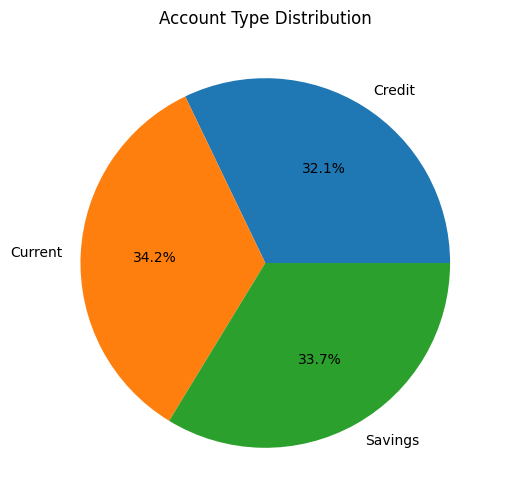

In [ ]:
account = df.groupby('Account_Type')['Amount'].sum()

plt.figure(figsize=(6,6))

account.plot(kind='pie', autopct='%1.1f%%')

plt.ylabel("")
plt.title("Account Type Distribution")

plt.show()

pie chart shows the account type contribution .

📊 Graph 4: Channel Usage (Bar Chart)

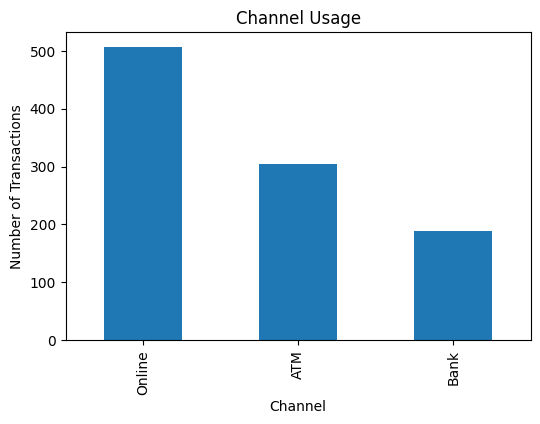

In [ ]:
channel = df['Channel'].value_counts()

plt.figure(figsize=(6,4))

channel.plot(kind='bar')

plt.title("Channel Usage")
plt.xlabel("Channel")
plt.ylabel("Number of Transactions")

plt.show()

this bar chart shows how much the channels are used respectively.

📊 Graph 5: Loan Status (Pie Chart)

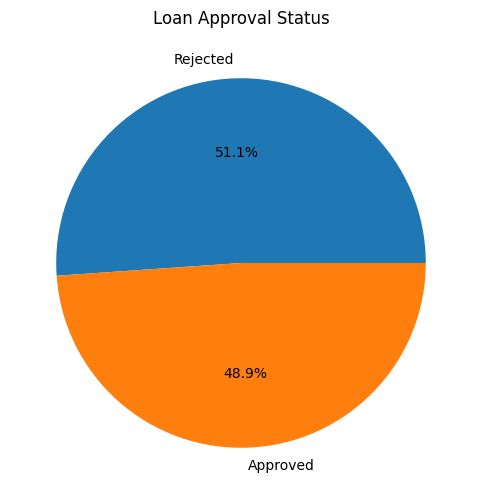

In [ ]:
loan = df['Loan_Status'].value_counts()

plt.figure(figsize=(6,6))

loan.plot(kind='pie', autopct='%1.1f%%')

plt.ylabel("")
plt.title("Loan Approval Status")

plt.show()

this pie chart shows how many loans are acceppted and rejected.